# Studiul Experimental al Prelucrării Paralele de Imagini în MPI

**Mediu de execuție:** Single Machine (Local Multi-Core) | **Rezoluție principală:** `8MP` (~25 MB per imagine necomprimată)

Acest studiu evaluează performanța implementării paralele bazate pe șablonul **Coordonator-Workers** în MPI pentru procesarea matricilor de pixeli RGB (format necomprimat **PPM `P6`**).

## 0. Verificarea Vizuală a Corectitudinii Operațiilor Grafice
Imaginea generată conține un marcaj roșu în stânga-sus, o grilă albă fină (1 px) și un cerc central galben. Aceste repere permit confirmarea corectitudinii algoritmilor de rotire, oglindire și asamblare a feliilor transmise prin MPI:

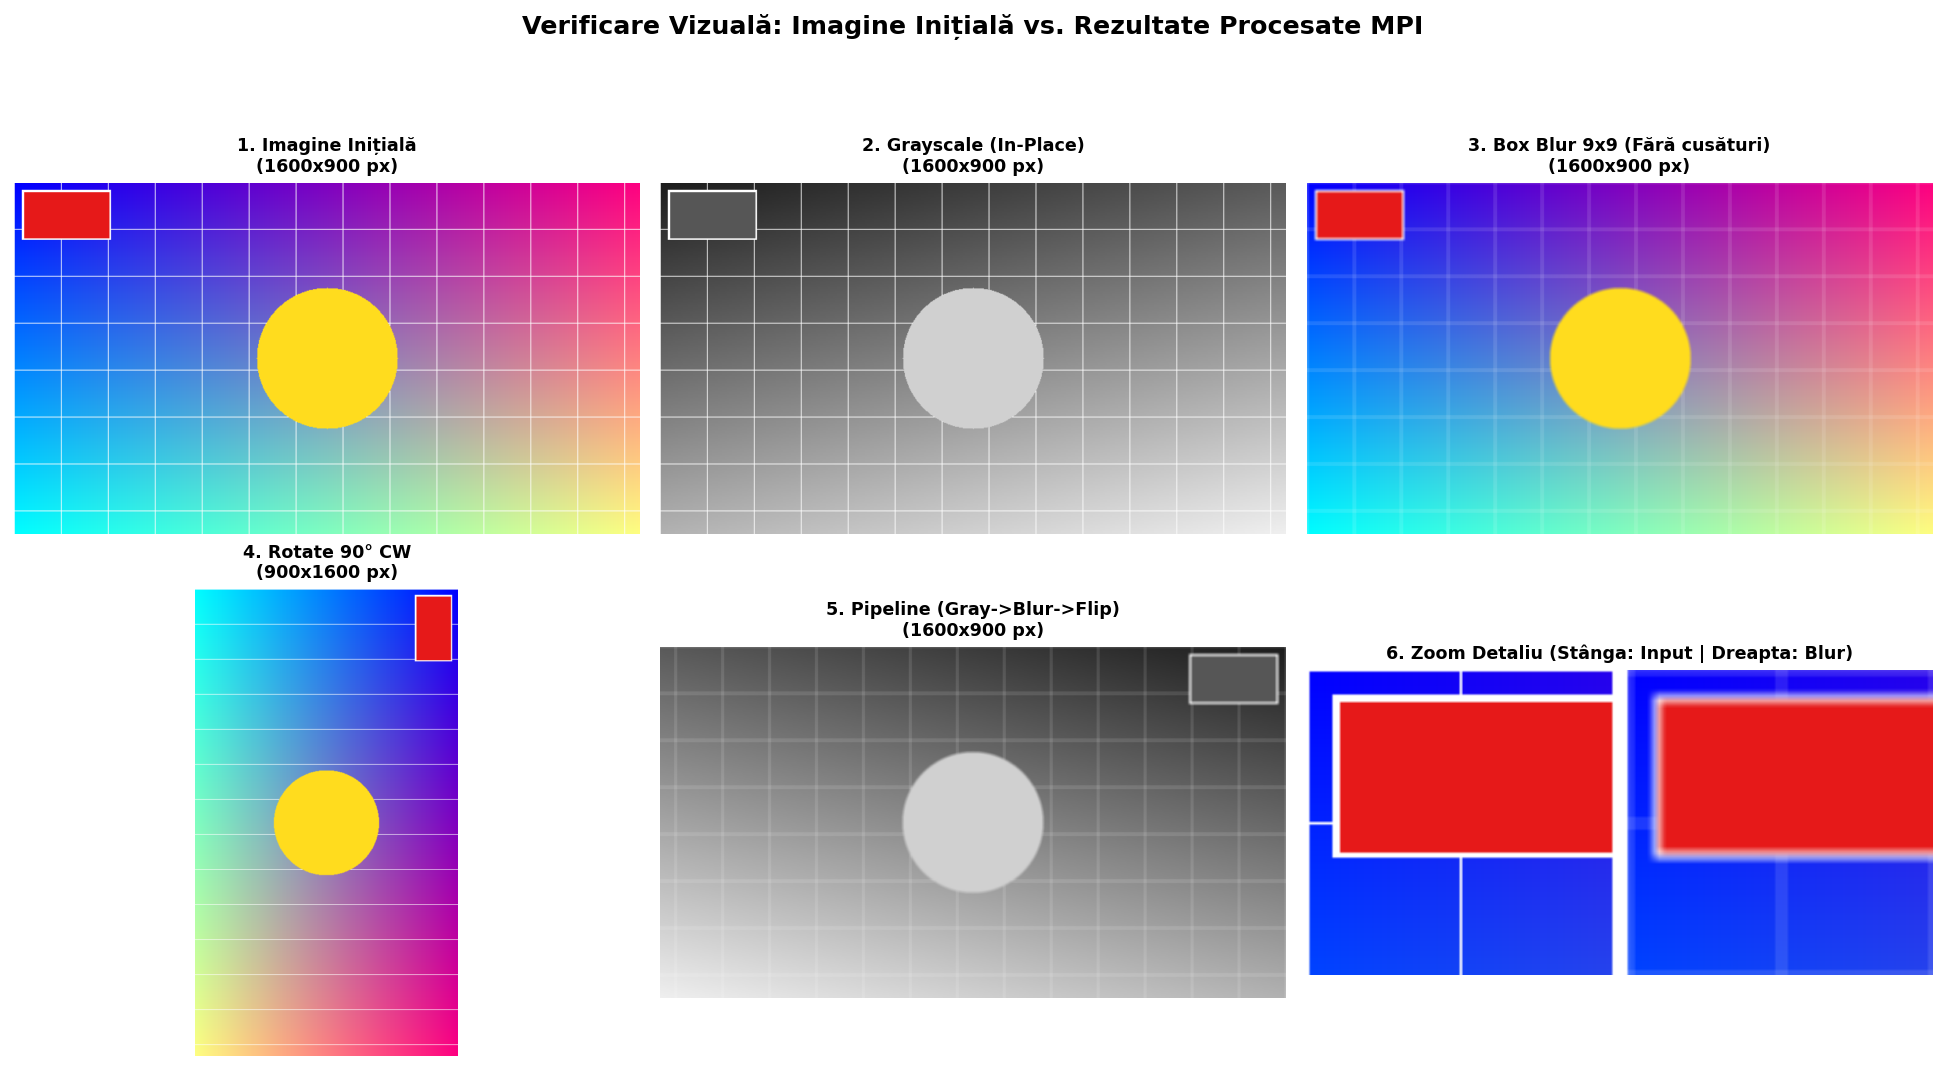


## 1. Variația Timpului de Execuție în Funcție de Numărul de Procese MPI (`np`)
**Concluzii experimentale:**
- **Operații cu calcul intensiv per pixel (`blur` și `pipeline`):** Timpul de execuție scade pronunțat pe măsură ce adăugăm workeri, evidențiind o scalabilitate puternică (Strong Scaling).
- **Operații simple (`grayscale`):** Complexitatea aritmetică redusă per pixel face ca timpul de transmitere a datelor prin memorie/rețea să limiteze câștigul paralel.
- **Saturația Hardware (Oversubscription):** Peste numărul de nuclee fizice/logice ale mașinii, panta se aplatizează sau începe să urce ușor din cauza context-switching-ului la nivel de OS.

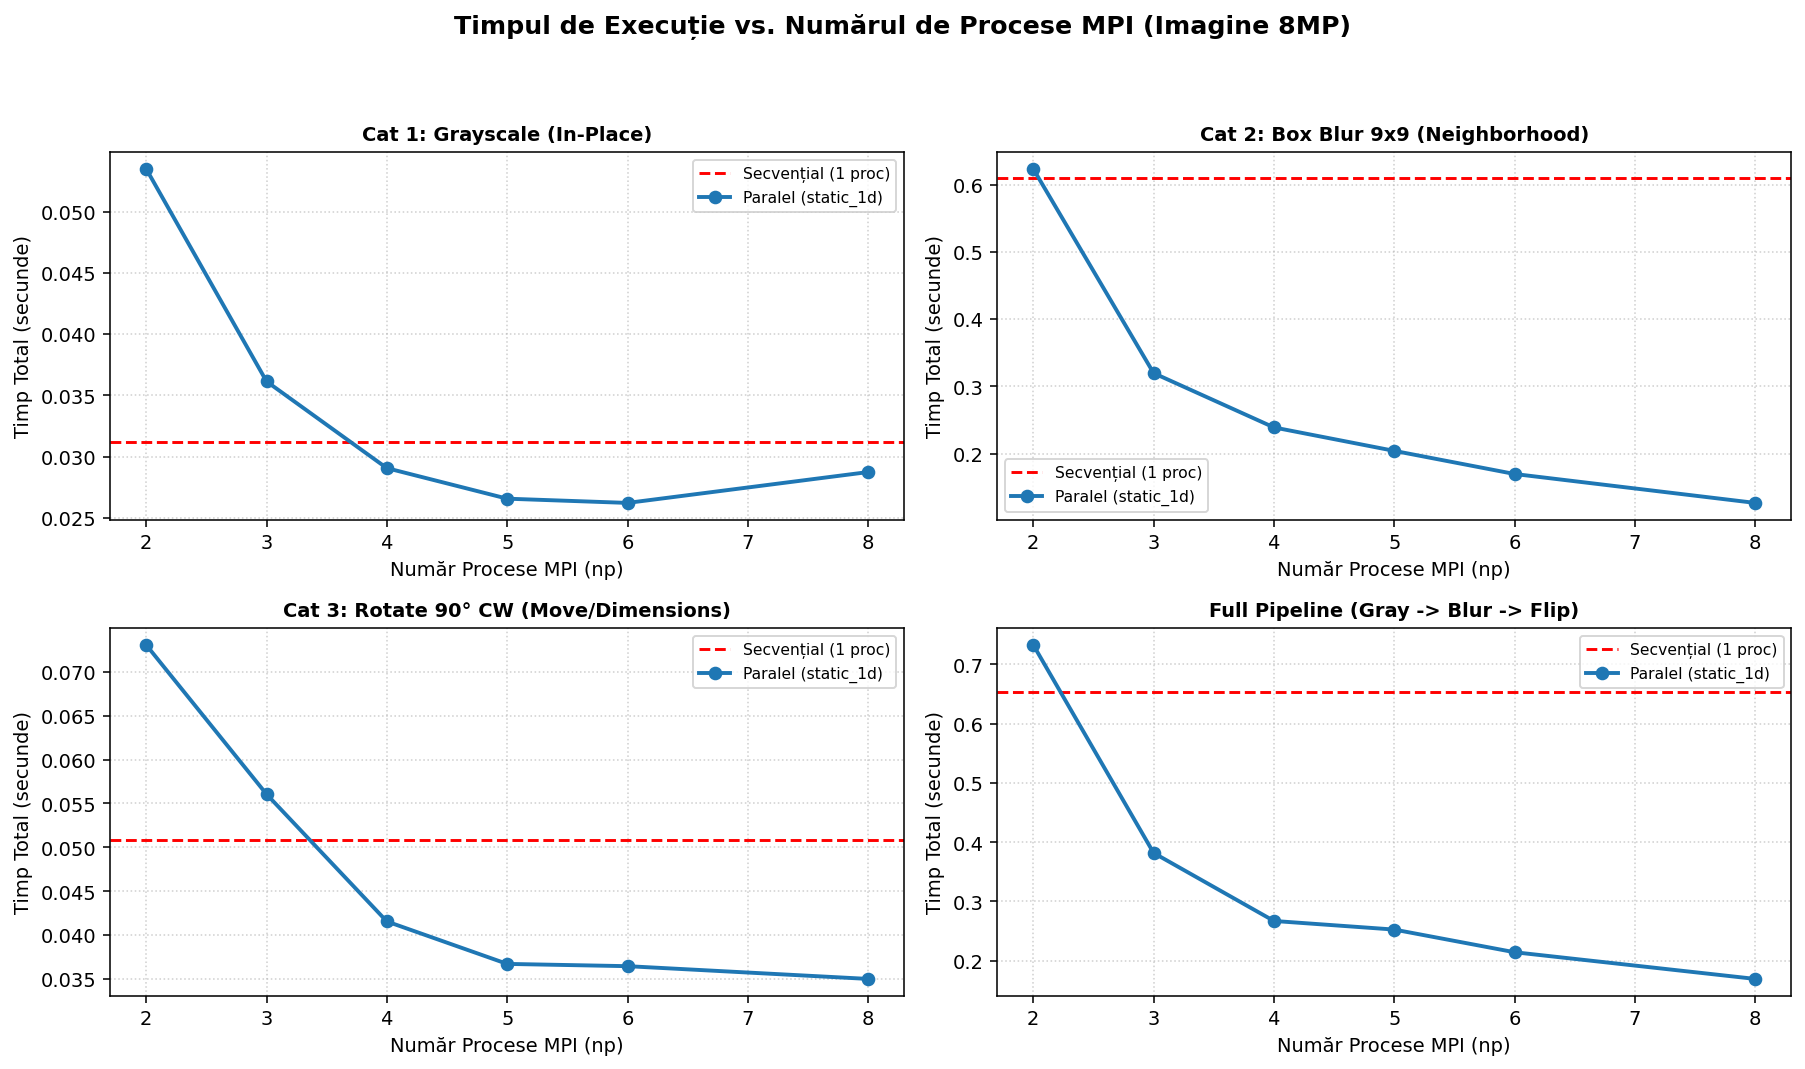


## 2. Analiza Speedup-ului Paralel ($S_p = \frac{T_{seq}}{T_{par}}$)
Speedup-ul măsoară accelerarea obținută comparativ cu execuția secvențială:
- Pentru filtrul **Box Blur**, volumul mare de operații aritmetice pe vecinătăți oferă un speedup solid pe arhitecturi multi-core.
- Pentru filtrul **Grayscale**, speedup-ul rămâne aproape de 1.0x-1.1x din cauza raportului mic între calcul și comunicație.

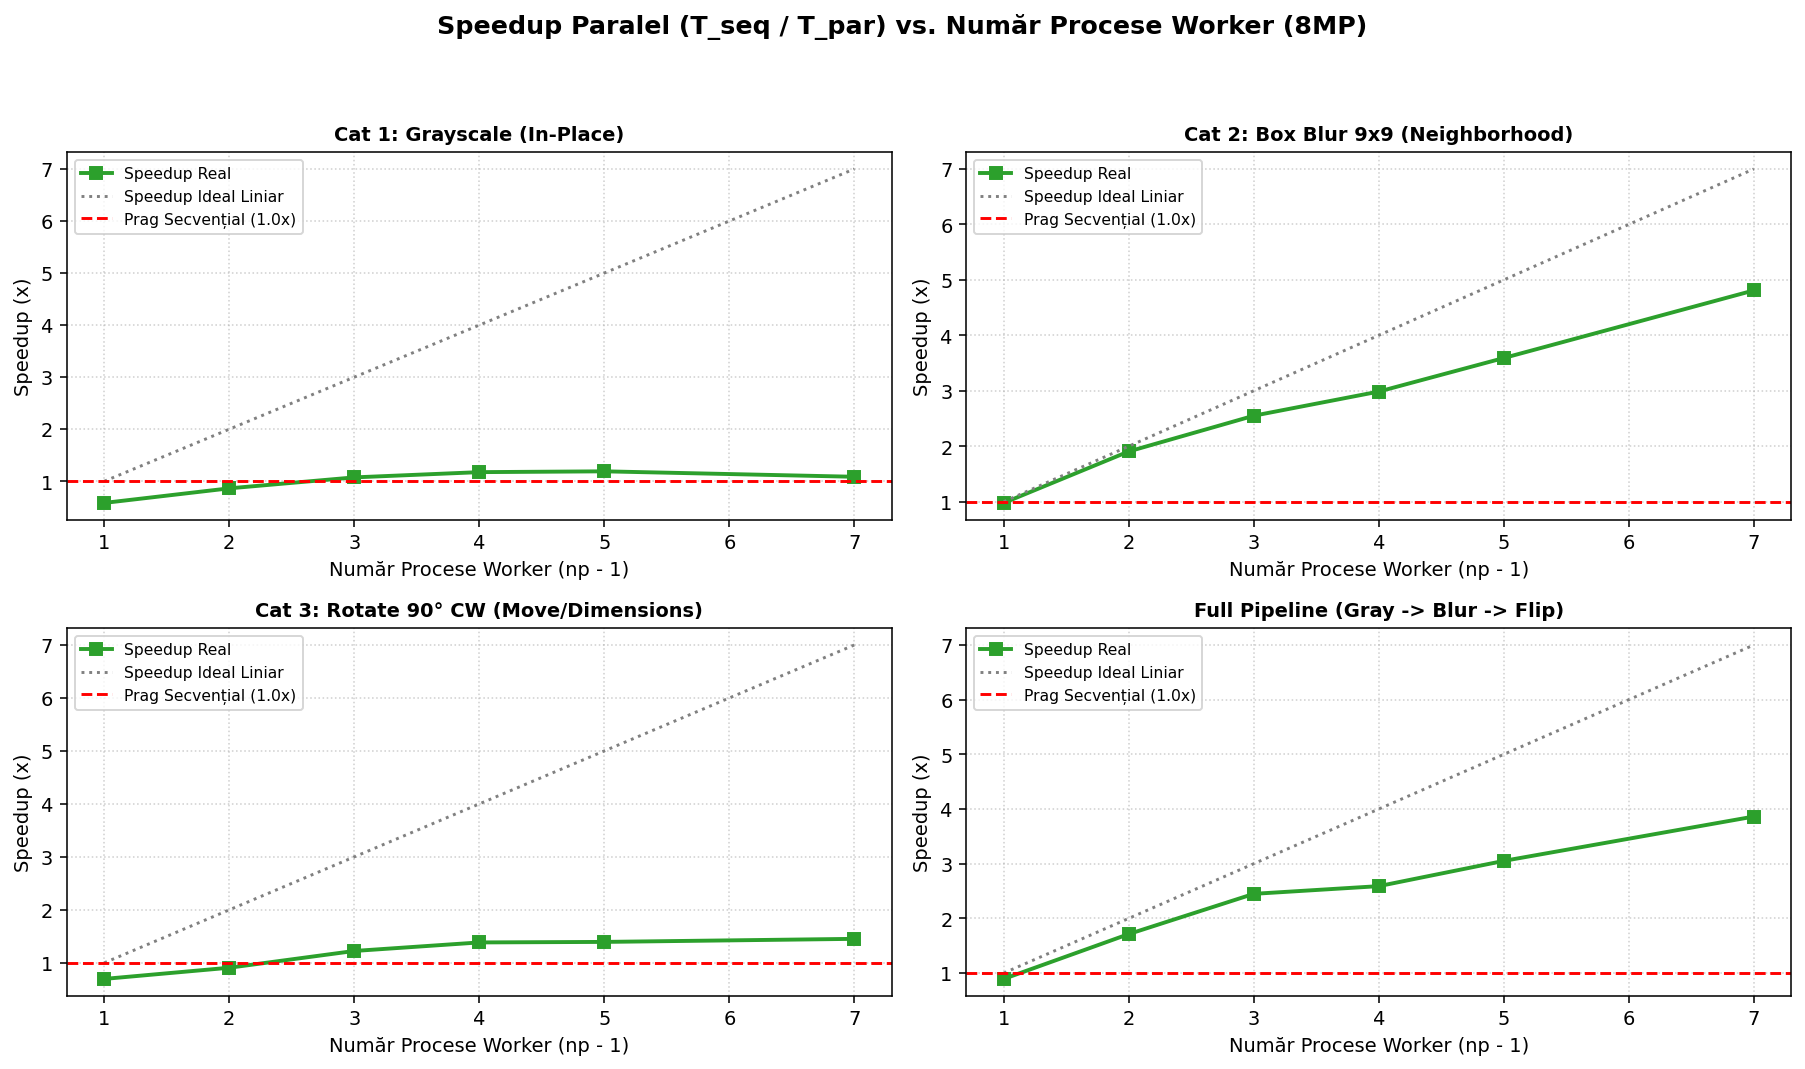


## 3. Scalabilitatea cu Rezoluția Imaginii ($N \times M$ Megapixeli)
Timpul de execuție crește liniar cu numărul de pixeli, conform complexității $O(N \cdot M)$. Pe imagini mari (8MP), panta execuției paralele este semnificativ mai mică decât cea secvențială, confirmând eficiența algoritmului paralel pe volume mari de date.

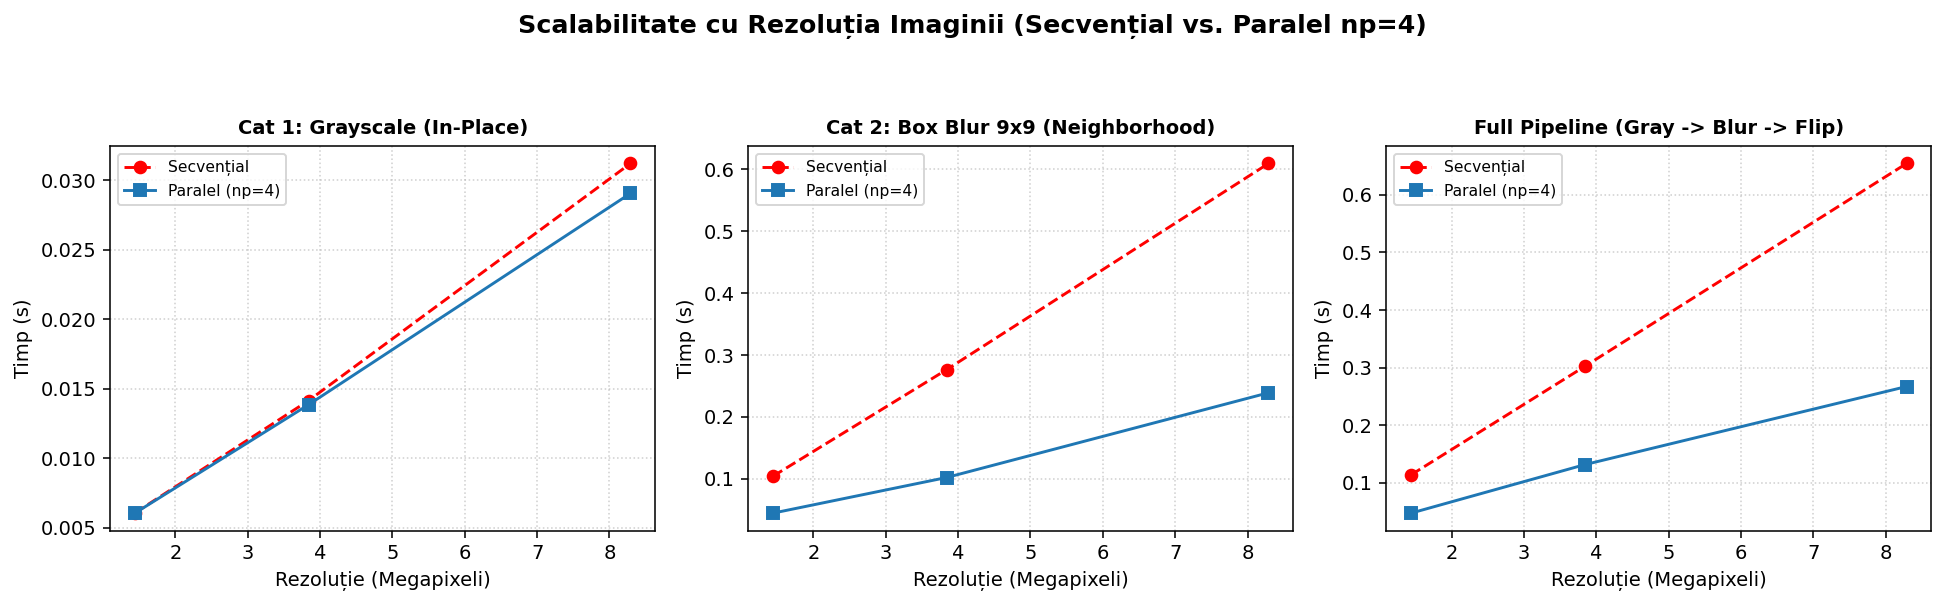


## 4. Comparația Strategiilor de Divizare (1D vs. 2D) și Load-Balancing (Static vs. Dinamic),
- **Divizare 1D vs. 2D:** Divizarea 1D orizontală este structural superioară divizării 2D în dale, deoarece ordinea *row-major* din C permite citirea directă a memoriei fără overhead-ul de împachetare (`pack_submatrix`) vizibil în bara portocalie a modului `static_2d`.
- **Static vs. Dinamic:** Deși `static_1d` transmite mai puține mesaje, **`dynamic_1d` obține cel mai bun timp de execuție**. Împărțirea în *chunk*-uri mai mici aduce două avantaje majore: o localitate a memoriei cache (L2/L3) superioară și eliminarea timpilor morți cauzați de fluctuațiile de frecvență ale nucleelor CPU (straggler effect).
- **Comportament pe cluster:** Avantajul modului dinamic va fi și mai pronunțat la conectarea a două laptopuri cu procesoare diferite.

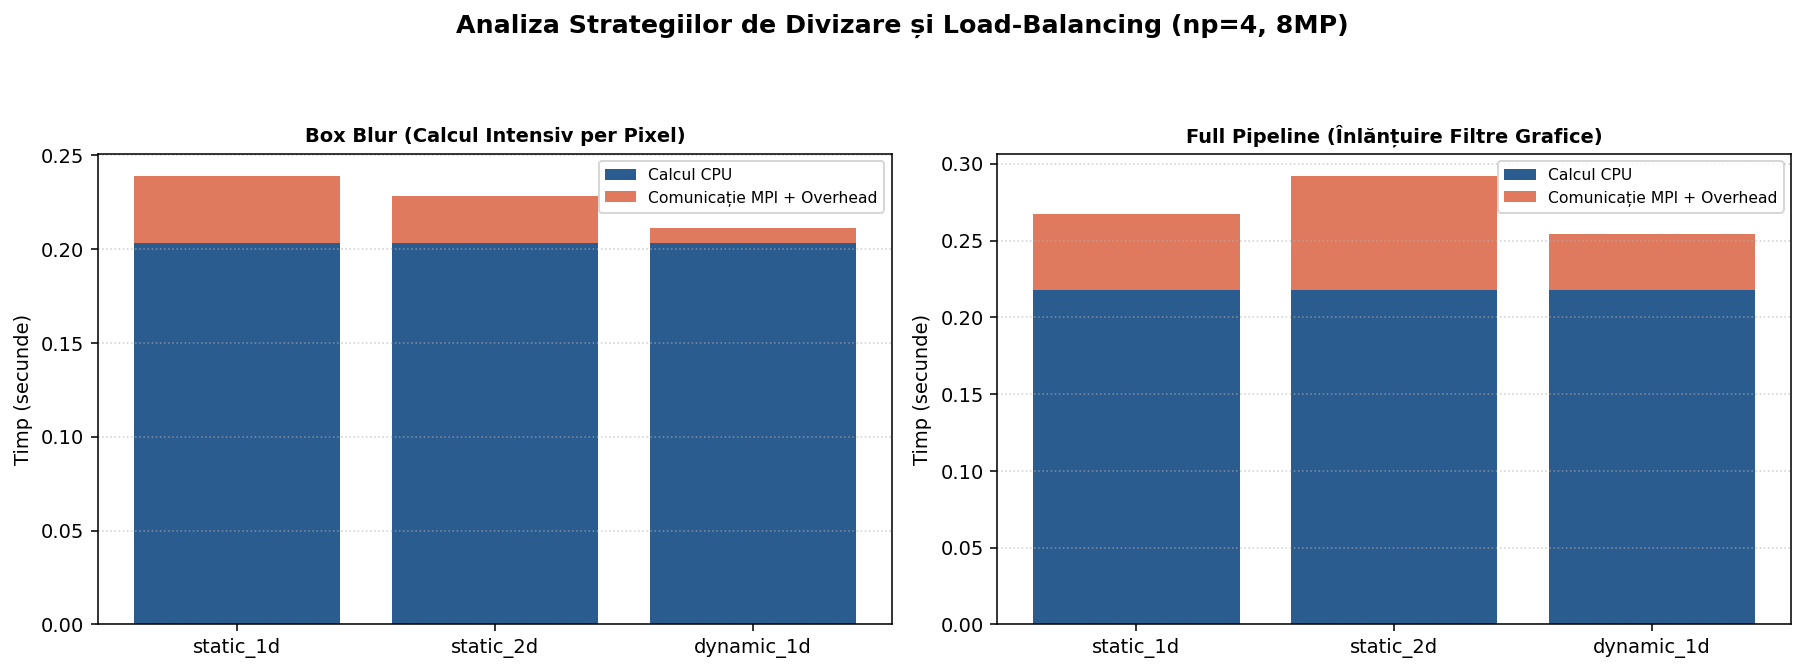


### Tabel Sintetic al Rezultatelor Măsurate (Rezoluție: `8MP`)

| Operație | Mod Paralelizare | Procese (`np`) | Workers | Timp Total (s) | Calcul CPU (s) | Comunicație MPI (s) | Speedup ($S_p$) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| `grayscale` | `seq` | 1 | 1 | **0.0312s** | 0.0312s | 0.0000s | **1.00x** |
| `grayscale` | `static_1d` | 2 | 1 | **0.0535s** | 0.0312s | 0.0223s | **0.58x** |
| `grayscale` | `static_1d` | 3 | 2 | **0.0361s** | 0.0156s | 0.0205s | **0.86x** |
| `grayscale` | `static_1d` | 4 | 3 | **0.0291s** | 0.0104s | 0.0187s | **1.07x** |
| `grayscale` | `static_1d` | 5 | 4 | **0.0266s** | 0.0078s | 0.0188s | **1.17x** |
| `grayscale` | `static_1d` | 6 | 5 | **0.0262s** | 0.0062s | 0.0200s | **1.19x** |
| `grayscale` | `static_1d` | 8 | 7 | **0.0287s** | 0.0045s | 0.0243s | **1.09x** |
| `blur` | `seq` | 1 | 1 | **0.6091s** | 0.6091s | 0.0000s | **1.00x** |
| `blur` | `static_1d` | 2 | 1 | **0.6232s** | 0.6091s | 0.0141s | **0.98x** |
| `blur` | `static_1d` | 3 | 2 | **0.3196s** | 0.3045s | 0.0151s | **1.91x** |
| `blur` | `static_1d` | 4 | 3 | **0.2389s** | 0.2030s | 0.0358s | **2.55x** |
| `blur` | `static_1d` | 5 | 4 | **0.2040s** | 0.1523s | 0.0517s | **2.99x** |
| `blur` | `static_1d` | 6 | 5 | **0.1696s** | 0.1218s | 0.0478s | **3.59x** |
| `blur` | `static_1d` | 8 | 7 | **0.1266s** | 0.0870s | 0.0396s | **4.81x** |
| `rotate90` | `seq` | 1 | 1 | **0.0509s** | 0.0509s | 0.0000s | **1.00x** |
| `rotate90` | `static_1d` | 2 | 1 | **0.0731s** | 0.0509s | 0.0222s | **0.70x** |
| `rotate90` | `static_1d` | 3 | 2 | **0.0561s** | 0.0254s | 0.0306s | **0.91x** |
| `rotate90` | `static_1d` | 4 | 3 | **0.0416s** | 0.0170s | 0.0246s | **1.22x** |
| `rotate90` | `static_1d` | 5 | 4 | **0.0367s** | 0.0127s | 0.0240s | **1.38x** |
| `rotate90` | `static_1d` | 6 | 5 | **0.0365s** | 0.0102s | 0.0263s | **1.39x** |
| `rotate90` | `static_1d` | 8 | 7 | **0.0350s** | 0.0073s | 0.0278s | **1.45x** |
| `grayscale,blur,flip` | `seq` | 1 | 1 | **0.6541s** | 0.6541s | 0.0000s | **1.00x** |
| `grayscale,blur,flip` | `static_1d` | 2 | 1 | **0.7328s** | 0.6541s | 0.0787s | **0.89x** |
| `grayscale,blur,flip` | `static_1d` | 3 | 2 | **0.3819s** | 0.3271s | 0.0548s | **1.71x** |
| `grayscale,blur,flip` | `static_1d` | 4 | 3 | **0.2672s** | 0.2180s | 0.0491s | **2.45x** |
| `grayscale,blur,flip` | `static_1d` | 5 | 4 | **0.2526s** | 0.1635s | 0.0891s | **2.59x** |
| `grayscale,blur,flip` | `static_1d` | 6 | 5 | **0.2144s** | 0.1308s | 0.0836s | **3.05x** |
| `grayscale,blur,flip` | `static_1d` | 8 | 7 | **0.1694s** | 0.0934s | 0.0759s | **3.86x** |
| `blur` | `static_2d` | 4 | 3 | **0.2283s** | 0.2030s | 0.0253s | **2.67x** |
| `blur` | `dynamic_1d` | 4 | 3 | **0.2111s** | 0.2030s | 0.0081s | **2.89x** |
| `grayscale,blur,flip` | `static_2d` | 4 | 3 | **0.2921s** | 0.2180s | 0.0740s | **2.24x** |
| `grayscale,blur,flip` | `dynamic_1d` | 4 | 3 | **0.2545s** | 0.2180s | 0.0365s | **2.57x** |
